In [1]:
import yaml
import sys
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
import PyComplexHeatmap as pch

from matplotlib import rcParams
# Type 2/TrueType fonts
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42
# Arial font
rcParams['font.sans-serif'] = "Arial"
rcParams['font.family'] = "sans-serif"

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

In [2]:
seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/fastq'
data_path = Path(config['DATADIR'])

# Syntax: sym_cellline_replicate
cell_line_dict=config['cell_lines']

# Stats of counts per guide

In [16]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

In [17]:
# the lowest we ever detect any guide in Pools is 217
gmin = df.loc[:, pools].min(1).min()
df_ = df.loc[:, pools].min(1).reset_index()
df_['NT guide'] = df.index.isin(controls)

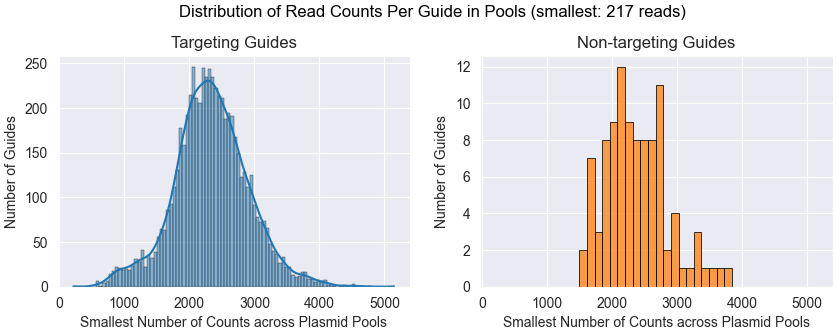

In [18]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(10, 3), sharex=True)
ax = axs[0]
sns.histplot(df_[~df_['NT guide']], x=0, bins=100, kde=True, color='tab:blue', label='Non-targeting Guides', ax=ax)
ax.set_xlabel('Smallest Number of Counts across Plasmid Pools')
ax.set_ylabel('Number of Guides')
ax.set_title('Targeting Guides')

ax = axs[1]
sns.histplot(df_[df_['NT guide']], x=0, bins=20, kde=False, color='tab:orange', label='Non-targeting Guides', ax=ax)
ax.set_xlabel('Smallest Number of Counts across Plasmid Pools')
ax.set_ylabel('Number of Guides')
ax.set_title(f'Non-targeting Guides')

pl.suptitle(f'Distribution of Read Counts Per Guide in Pools (smallest: {gmin} reads)', y=1.05)
pl.savefig('../results/qc_plots/hist_read_counts_per_guide_in_plasmid_pools.pdf', bbox_inches='tight')
pl.show()

# Correlation between guides targeting the same target

In [25]:
# Load Data
df = pd.read_csv(Path(config['DATADIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]
df['essential'] = annotate_essentiality(df.Gene)

# Normalize to NT depth
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None
l2fc['Transcript_ID'] = df.Transcript_ID.copy()
l2fc['Gene'] = df.Gene.copy()

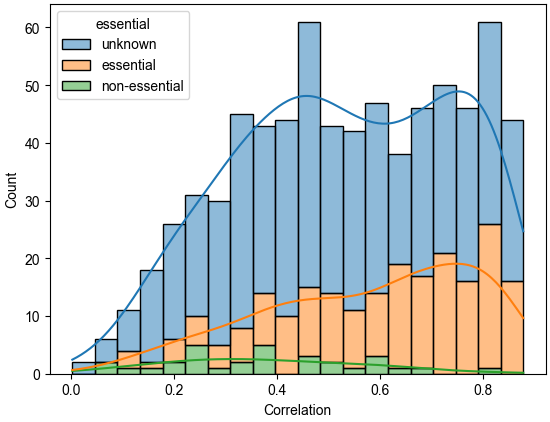

In [52]:
# Calculate the correlation between guides targeting the same gene
corr = l2fc.groupby('Gene').corr().mean(1).reset_index().groupby('Gene').mean()
corr['essential'] = annotate_essentiality(corr.index)
corr.rename(columns={0: 'Correlation'}, inplace=True)
sns.histplot(corr, x='Correlation', bins=20, kde=True, hue='essential', multiple="stack")
pl.savefig('../results/qc_plots/hist_correlation_between_guides_per_gene.pdf', bbox_inches='tight')
pl.show()

# Evaluate guide counting /alignment to screen

In [36]:
alignment_qc = pd.read_csv('../results/multiqc/multiqc_data/mqc_samtools_alignment_plot_1.txt', sep='\t', index_col=0)
alignment_qc['sample_id'] = [x.split('_L00')[0] for x in alignment_qc.index ]
alignment_qc = alignment_qc.groupby('sample_id').mean()  # merge lanes
alignment_qc['cell_line'] = [x.split('-')[1] for x in alignment_qc.index ]
alignment_qc['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-5] for x in alignment_qc.index ]
alignment_qc['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in alignment_qc.index ]
alignment_qc['total_reads'] = alignment_qc.sum(1)
alignment_qc['fraction_mapped'] = alignment_qc['Mapped (with MQ>0)'] / alignment_qc['total_reads']
alignment_qc['cell_line_x_replicate'] = [f'{x}_{y}' for x, y in zip(alignment_qc.cell_line, alignment_qc.replicate)]

In [37]:
alignment_qc.head()

,Mapped (with MQ>0),MQ0,Unmapped,cell_line,replicate,time_point,total_reads,fraction_mapped,cell_line_x_replicate
sample_id,,,,,,,,,
Sym-pool-1-1_S55,7307020.0,16558.5,839944.5,pool,01,Pool,8163523.0,0.895082,pool_01
Sym-pool-1-2_S56,7537046.5,17021.5,869385.0,pool,02,Pool,8423453.0,0.894769,pool_02
Sym-pool-1-3_S57,10628643.0,23437.5,1195156.5,pool,03,Pool,11847237.0,0.897141,pool_03
sym-01-01-TP1_S1,9467214.5,24451.5,1199081.0,01,01,TP1,10690747.0,0.885552,01_01
sym-01-01-TP2_S4,8729435.5,22546.5,1078416.5,01,01,TP2,9830398.5,0.888004,01_01


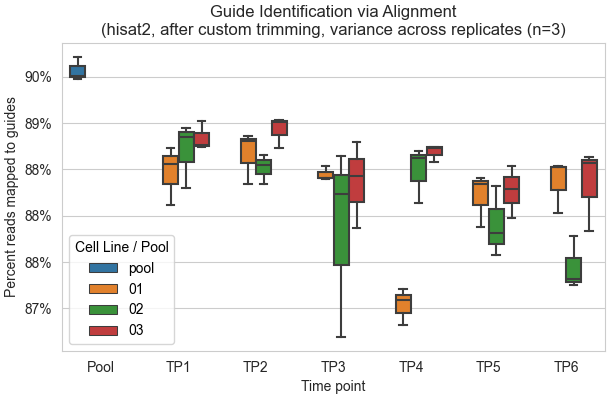

In [44]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(7,4))
sns.boxplot(data=alignment_qc.reset_index(), x='time_point', y='fraction_mapped', ax=ax, hue='cell_line', dodge=True)
import matplotlib.ticker as mtick
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_ylabel('Percent reads mapped to guides')
ax.set_xlabel('Time point')
ax.set_title('Guide Identification via Alignment\n(hisat2, after custom trimming, variance across replicates (n=3)')
pl.savefig('../results/qc_plots/qc_mapping_guide_alignment.pdf', bbox_inches='tight')
pl.legend(loc='lower left', title='Cell Line / Pool')
pl.show()

# Sample Correlation

In [8]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

In [9]:
df.head()

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1494,1747,1655,1494,1545,1298,1388,1842,1277,1391
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,2072,2450,2161,2318,2164,1774,2055,2276,1863,2168
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1299,1680,1402,1473,1463,1166,1192,1650,1139,1391
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,1175,1268,1071,1026,1157,892,976,1263,835,1073
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1898,2201,1797,1975,2039,1678,1794,2248,1576,1842


In [11]:
# Calculate pairwise correlations between samples
pairwise_correlations = pd.DataFrame(index=sample_names, columns=sample_names, dtype=float)
for i in sample_names:
    for j in sample_names:
        pairwise_correlations.loc[i, j] = np.corrcoef(df.loc[:, i], df.loc[:, j])[0, 1]

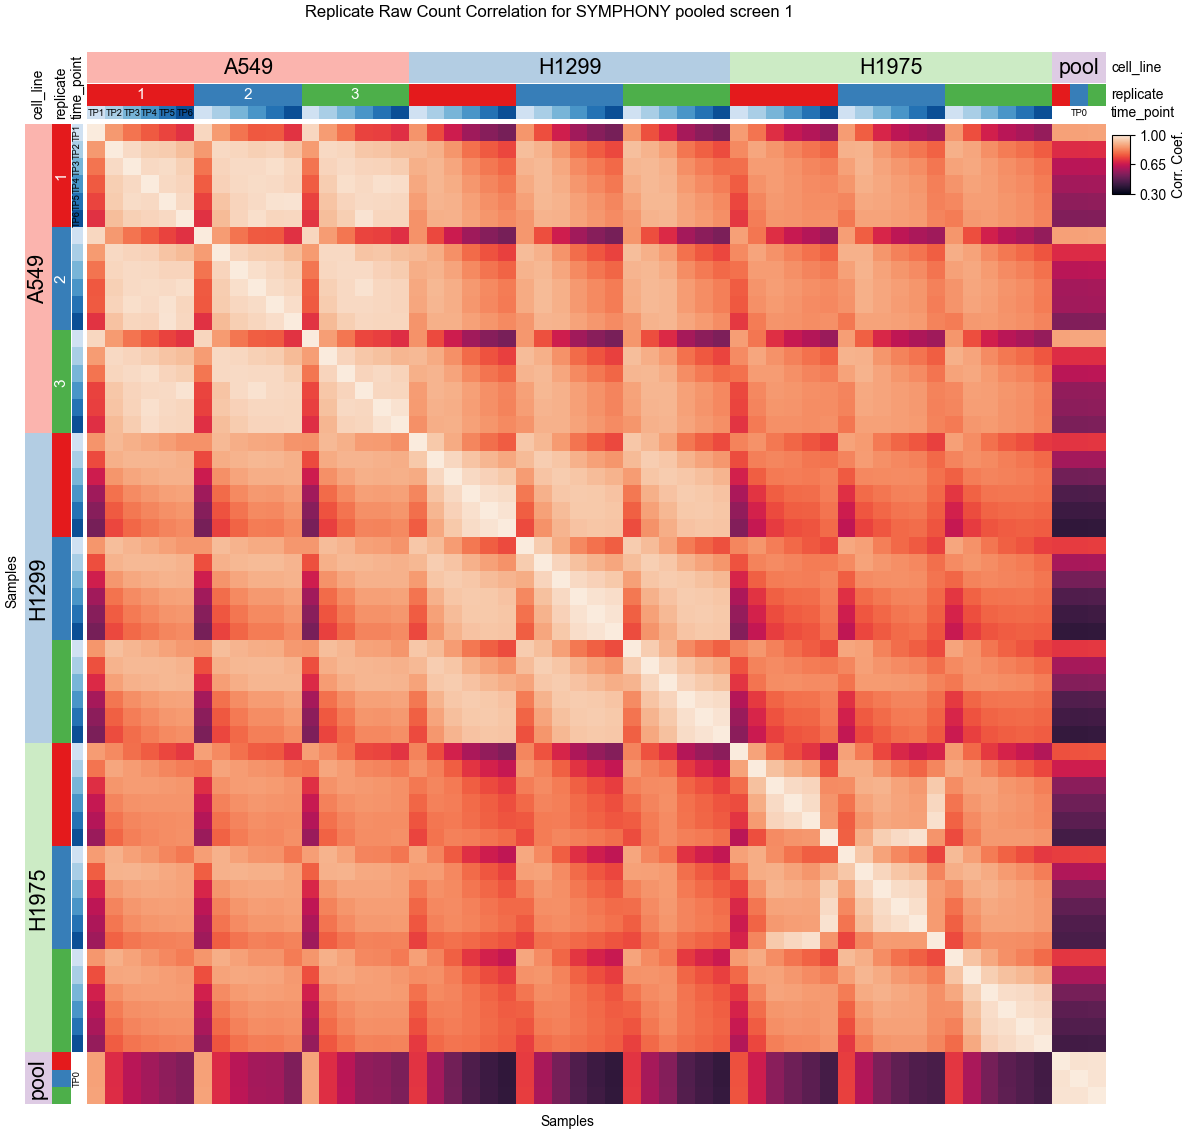

In [44]:
# Prepare annotation
cell_line = pd.Series({x: cell_line_dict[int(x.split('-')[1])] if x.split('-')[1]!='pool' else 'pool' for x in sample_names})
replicate = pd.Series({x: x.split('-')[2][-1] if 'pool' not in x else x.split('-')[-1] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] if 'pool' not in x else 'TP0' for x in sample_names})
order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 1, 2]).index  # sort by time before replicate

# select and reorder
data = pairwise_correlations.loc[order, order]

# Create the colormap
from matplotlib.colors import LinearSegmentedColormap
cmap = sns.color_palette('Blues', as_cmap=True)
colors = [cmap(x) for x in np.linspace(0.2, 0.9, 7)] + [(1, 1, 1, 1)]  # white for TP0
time_cmap = LinearSegmentedColormap.from_list("gradual_colormap", colors, N=7)

annot_kwargs = dict(
    cell_line=pch.anno_simple(cell_line.loc[order], add_text=True, height=7, cmap='Pastel1'),
    replicate=pch.anno_simple(replicate.loc[order], add_text=True, height=5),
    time_point=pch.anno_simple(time_point.loc[order], add_text=True, height=3, cmap=time_cmap),
    verbose=0, plot_legend=False
)
top_ha = pch.HeatmapAnnotation(axis=1, **annot_kwargs)
left_ha = pch.HeatmapAnnotation(axis=0, **annot_kwargs)

pl.figure(figsize=(14, 12))
cm = pch.ClusterMapPlotter(
    data=data, left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=0.3, vmax=1,
    legend_kws=dict(label='Corr. Coef.'),
    xlabel="Samples", ylabel='Samples', legend_hpad=0,
    verbose=0
)
pl.suptitle('Replicate Raw Count Correlation for SYMPHONY pooled screen 1', y=0.92)
pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.png', dpi=300)
pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.pdf', dpi=300)
pairwise_correlations.to_csv('../results/qc_plots/qc_correlation_source_data.csv')
pl.show()

# Estimation of guide failure chance, given that the target is a hit

Assumptions:
- Guides follow a binomial distribution
    - Guides are independent (this is not true, but we can still get a lower bound)
    - Guides are equally likely to fail or to succeed
- We always correctly called hits and no-hits in our 101 screen
- For simplicity, we call a target a hit if at least half of all guides are hits

Given a number of guides $N$, we check how high the chance for calling a false negative or positive is. 
In other words, how likely is it that more than half of the guides are no hits, given that the target is a hit (and same for false positives).

In [7]:
# options
fdr_cutoff = 0.05
log2fc_cutoff = -0.5
feature = 'transcript'  # gene or transcript

In [8]:
# Get hits in our screen
tab = pd.read_csv(f'../results/merged/{feature}_results_perline.csv', index_col=0, header=[0, 1])
# Take smallest fdr and largest lfc across lines (we only care if transcript is a hit in any cell line)
fdr = tab.loc[:, (slice(None), 'MAGeCK_filtered_fdr')].min(axis=1)
lfc = tab.loc[:, (slice(None), 'MAGeCK_filtered_lfc')].min(axis=1)
hits = np.array(tab.loc[(fdr < fdr_cutoff) & (lfc < log2fc_cutoff), :].index)
print(f'Found {len(hits)} hits among {len(tab)} targets in our screen')

Found 292 hits among 844 targets in our screen


In [9]:
# Get guide-level results
guide_df = pd.read_csv('../results/merged/guide_results_perline.csv', index_col=0, header=[0, 1]).loc[:, (slice(None), 'MAGeCK_FDR')].min(axis=1).to_frame().rename(columns={0: 'FDR'})
guide_df['target'] = guide_df.index.str.split('_').str[1]
# Load Data
df = pd.read_csv(Path(config['DATADIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]
# Normalize to NT depth
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor
# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

guide_df = pd.concat([guide_df, l2fc.min(axis=1).loc[guide_df.index]], axis=1).rename(columns={0: 'L2FC'})
guide_df['targets_hit'] = guide_df.target.isin(hits)
guide_df['is_significant'] = (guide_df.FDR < fdr_cutoff) & (guide_df.L2FC < log2fc_cutoff)
guide_df = pd.merge(guide_df, df.loc[:, ['Region', 'transcript_biotype']], left_index=True, right_index=True)

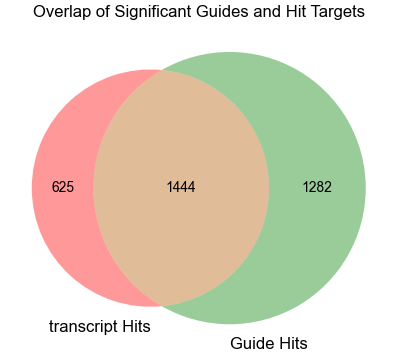

In [10]:
set1 = set(guide_df[guide_df.targets_hit].index)
set2 = set(guide_df[guide_df.is_significant].index)
# make venn diagram
from matplotlib_venn import venn2
pl.figure(figsize=(5, 5))
venn2([set1, set2], set_labels=(f'{feature} Hits', 'Guide Hits'))
pl.title('Overlap of Significant Guides and Hit Targets')
pl.show()

In [11]:
sdf = guide_df# [guide_df.transcript_biotype == 'lncRNA']
confusion_rates = (sdf.value_counts(['targets_hit', 'is_significant']) / len(sdf)).pipe(lambda x: x.unstack().fillna(0))  # make table
confusion_rates*100

is_significant,False,True
targets_hit,,
False,46.168675,20.594378
True,10.040161,23.196787


In [12]:
# Model assuming we need all guides to fail to miss a hit
N = 3  # number of guides per target
false_negative_rate = confusion_rates.loc[False, True] ** N  # chance that all guides fail to detect a hit
false_positive_rate = confusion_rates.loc[True, False] ** N  # chance that all guides are false positives
print(f'Given {N} guides per target, we have a {false_negative_rate*100:.2f}% chance of missing a hit and a {false_positive_rate*100:.2f}% chance of a false positive.')

Given 3 guides per target, we have a 0.87% chance of missing a hit and a 0.10% chance of a false positive.


In [13]:
# Model assuming we need more than half of guides to fail to miss a hit
from scipy.stats import binom
N_max = 10  # number of guides per target
rates = {}
for N in range(1, N_max+1):
    n = N//2  # number of guides that need to fail to miss a hit
    p = confusion_rates.loc[True, False]  # chance that a single guide fails to detect a true hit
    fn_rate = 1-binom.cdf(n, N, p)  # 1 - Chance that n or fewer guides fail to detect a true hit (false negative rate)
    
    p = confusion_rates.loc[False, True]  # chance that a single guide fails to detect a false hit
    fp_rate = 1-binom.cdf(N-n, N, p)  # 1 - Chance that n or fewer guides fail to detect a false hit (false positive rate)
    
    rates[N] = [fn_rate, fp_rate]
res = pd.DataFrame(rates, index=['False Negative Rate', 'False Positive Rate'])
res

,1,2,3,4,5,6,7,8,9,10
False Negative Rate,0.100402,0.010080,0.028217,0.003744,0.008658,0.001290,0.002769,0.000440,0.000908,0.000150
False Positive Rate,0.000000,0.042413,0.008735,0.029542,0.007512,0.018855,0.005345,0.011837,0.003589,0.007411


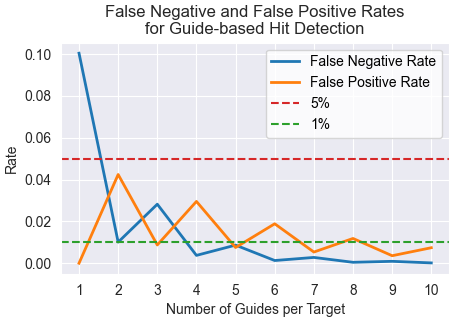

In [14]:
# TODO: repeat for lncRNA
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(5,3))
pl.plot(res.loc['False Negative Rate'], label='False Negative Rate', linewidth=2)
pl.plot(res.loc['False Positive Rate'], label='False Positive Rate', linewidth=2)
pl.axhline(0.05, color='tab:red', linestyle='--', label='5%')
pl.axhline(0.01, color='tab:green', linestyle='--', label='1%')
pl.legend()
ax.set_xticks(range(1, N_max+1))
pl.xlabel('Number of Guides per Target')
pl.ylabel('Rate')
pl.title('False Negative and False Positive Rates\nfor Guide-based Hit Detection')
pl.savefig('../results/qc_plots/guide_based_hit_detection_rates.pdf', bbox_inches='tight')
pl.show()

In [15]:
guide_df

,FDR,target,L2FC,targets_hit,is_significant,Region,transcript_biotype
RPL10_ENST00000436473_467,1.242500e-158,ENST00000436473,-7.357992,True,True,CDS,protein_coding
RAN_ENST00000535090_324,2.246800e-147,ENST00000535090,-7.484012,True,True,CDS,protein_coding
ACTG1_ENST00000573283_1731,1.188200e-144,ENST00000573283,-11.052936,True,True,UTR3,protein_coding
RPL14_ENST00000416518_279,3.596700e-142,ENST00000416518,-11.030467,True,True,CDS,protein_coding
CCT8_ENST00000286788_1903,1.269300e-139,ENST00000286788,-7.091635,True,True,UTR3,protein_coding
...,...,...,...,...,...,...,...
UBE2I_ENST00000397514_282,1.761100e-07,ENST00000397514,-1.066709,True,True,CDS,protein_coding
SRRM1_ENST00000323848_574,1.597000e-02,ENST00000323848,-0.299847,True,False,CDS,protein_coding
UBE2D3_ENST00000394803_368,4.717100e-03,ENST00000394803,-0.609406,True,True,CDS,protein_coding
NFE2L1_ENST00000357480_1853,1.601700e-01,ENST00000357480,-0.293552,True,False,CDS,protein_coding
